In [1]:
# =============================================================================
# CELL 1 -- Configuration, imports and style
#
# FIG 1 (impact-parameter map + flux, for one halo of TNG50-2). FIG 2 (the
# single-sightline HCD-detection figure) and the pixel-resolution diagnostic
# that used to live in this notebook have moved to
# 01.5.1_TNG50_individual.ipynb, which reuses this notebook's HALO_ID so both
# figures describe the same halo.
#
# Produces:
#   FIG 1  plots/diff_impact_parameters_visualization_altHalo.pdf
#
# Decomposition: "peaks+blend" -- velocity-space watershed with peak persistence
# plus the F_sep flux blending test of Sec. 2.3 (relevant to the HCD_only /
# Forest_only split used by FIG 1's flux panel).
# =============================================================================
%matplotlib widget

import os
import sys
from contextlib import contextmanager

import numpy as np
import h5py
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.signal import fftconvolve

REPO_DIR = os.path.abspath("..")          # notebooks_TNG/ -> FakeSpectra_DLAs/
sys.path.insert(0, os.path.join(REPO_DIR, "tools"))

import utils
import radii_skewers
from fake_spectra import spectra

if not hasattr(spectra, "HCD_ALGORITHMS"):
    raise ImportError(f"{spectra.__file__} is not the HCD fork "
                      "(no HCD_ALGORITHMS)")
print("using:", spectra.__file__)
print("algorithms:", spectra.HCD_ALGORITHMS)

# --- simulation --------------------------------------------------------------
SIM_NAME  = "TNG50-2"
BASE_PATH = f"/home/STORAGE/{SIM_NAME}"   # no "/output": groups_025/ lives here
SNAP_NUM  = 25                            # z ~ 3.01
SIM_TYPE  = "TNG"

# --- what to plot ------------------------------------------------------------
HALO_ID = 25            # fixed: same halo used by 01.5.1_'s FIG 2
SEED    = 12345

NUM_PARAM_IMPACTS = 30
RANGE_PARAM_IMPACTS = (0.01, 50.0)
HCD_LOG_NHI = 17.2

# FIG 1
B_LIST_TARGET  = (0.2, 0.4)
MAP_AXIS       = 2        # 0=x, 1=y, 2=z. The caption says "along z".
MAP_HALF_R200  = 1.5
MAP_SLAB_R200  = 5.0      # matches the +/-5 R200 aperture of Sec. 2.4
MAP_NPIX       = 400      # fixed; smoothing is adaptive per cell
MAP_H_MAX_R200 = 0.25     # cap on a cell's smoothing radius, in R200
MAP_VMIN_LOGN  = 15.0     # colour floor; raise it if the panel saturates
MAP_VMAX_LOGN  = None     # None -> 99.9th pct of the pixels above the floor
SHOW_HCD_CONTOUR = True

PLOT_DIR = os.path.join(REPO_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

# --- style -------------------------------------------------------------------
plt.rc('font', family='serif', size=16)
plt.rcParams.update({
    "mathtext.fontset": "cm", "text.usetex": False,
    "axes.linewidth": 1.6, "axes.grid": False,
    "axes.labelsize": 19, "legend.fontsize": 15,
    "xtick.labelsize": 16, "ytick.labelsize": 16,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
    "xtick.major.size": 8, "ytick.major.size": 8,
    "xtick.minor.size": 4, "ytick.minor.size": 4,
    "xtick.major.width": 1.4, "ytick.major.width": 1.4,
    "xtick.minor.visible": True, "ytick.minor.visible": True,
    "legend.frameon": True, "legend.framealpha": 0.92,
    "figure.dpi": 72, "savefig.dpi": 300, "savefig.bbox": "tight",
})

# Okabe-Ito, verbatim from the manuscript preamble.
colors = [
    "#E69F00",  # 0. Orange
    "#56B4E9",  # 1. Sky Blue
    "#009E73",  # 2. Bluish Green
    "#F0E442",  # 3. Yellow
    "#0072B2",  # 4. Blue
    "#D55E00",  # 5. Vermillion
    "#CC79A7",  # 6. Reddish Purple
    "#000000",  # 7. Black
    "#999999",  # 8. Grey
    "#553388",  # 9. Purple
]
OI = {"orange": colors[0], "sky": colors[1], "green": colors[2],
      "yellow": colors[3], "blue": colors[4], "vermillion": colors[5],
      "purple": colors[6], "black": colors[7], "grey": colors[8],
      "violet": colors[9]}
plt.rcParams["axes.prop_cycle"] = mpl.cycler(color=colors)

# N_HI-class colours (Prochaska+2005 / Ho, Bird & Garnett 2021 edges -- see
# radii_skewers.CATEGORY_EDGES/CATEGORY_LABELS), for any figure that colours
# skewers or pixels by absorber class rather than by impact parameter.
CLASS_COLORS = {
    "Forest":    "#E69F00",
    "LLS":       "#56B4E9",
    "Sub_DLA":   "#009E73",
    "Small_DLA": "#F0E442",
    "Large_DLA": "#0072B2",
}

M_SUN_G, KPC_CM, M_P_G = 1.98847e33, 3.085678e21, 1.67262192e-24
X_H_DEFAULT = 0.76


using: /home/vroberto/fake_spectra_fork/fake_spectra/spectra.py
algorithms: ('peaks', 'peaks+blend', 'region_growing')


In [2]:
# =============================================================================
# CELL 2 -- Suppress the C interpolator's stdout noise
#
# fake_spectra's C extension writes its progress bar to file descriptor 1
# directly, bypassing Python's sys.stdout -- silence it around each snapshot
# read, or it floods the notebook output.
# =============================================================================
@contextmanager
def suppress_c_stdout():
    """Silence the C interpolator's progress printing (it writes to fd 1)."""
    sys.stdout.flush()
    saved = os.dup(1)
    devnull = os.open(os.devnull, os.O_WRONLY)
    try:
        os.dup2(devnull, 1)
        yield
    finally:
        os.dup2(saved, 1)
        os.close(devnull)
        os.close(saved)


In [3]:
# =============================================================================
# CELL 3 -- Impact-parameter grid, simulation context, halo finder
# =============================================================================
def build_r_multipliers(n_impacts, impact_min, impact_max):
    return np.insert(np.logspace(np.log10(impact_min), np.log10(impact_max),
                                 n_impacts), 0, 0.0)


R_MULTIPLIERS = build_r_multipliers(NUM_PARAM_IMPACTS, *RANGE_PARAM_IMPACTS)


def snap_impact(b_target, grid=R_MULTIPLIERS):
    """Nearest grid value to b_target, in log space (the grid is log-spaced)."""
    pos = grid[grid > 0]
    k = int(np.argmin(np.abs(np.log10(pos) - np.log10(b_target))))
    return float(pos[k]), k


def wrap(d, period):
    """Signed separation on a periodic axis, in (-period/2, +period/2]."""
    return (np.asarray(d) + period / 2.0) % period - period / 2.0


B_LIST = [snap_impact(b)[0] for b in B_LIST_TARGET]
print(f"FIG 1 b: {B_LIST_TARGET} -> {[f'{b:.4f}' for b in B_LIST]} R200")

ctx = utils.SimulationContext(BASE_PATH, SNAP_NUM, sim_type=SIM_TYPE)
finder = utils.HaloFinder(ctx)

for _p in (os.path.join(BASE_PATH, f"groups_{SNAP_NUM:03d}",
                        f"fof_subhalo_tab_{SNAP_NUM:03d}.0.hdf5"),
           os.path.join(BASE_PATH, f"snapdir_{SNAP_NUM:03d}")):
    if not os.path.exists(_p):
        raise FileNotFoundError(f"not found: {_p}\nCheck BASE_PATH={BASE_PATH!r}")


FIG 1 b: (0.2, 0.4) -> ['0.1886', '0.4552'] R200


In [4]:
# =============================================================================
# CELL 4 -- Halo used by FIG 1 (fixed HALO_ID, shared with 01.5.1_'s FIG 2)
# =============================================================================
halo_info = finder.get_halo_properties(int(HALO_ID))
r200 = float(halo_info['r200'])

print(f"halo {HALO_ID}")
print(f"  log10(M200/Msun) = {np.log10(halo_info['mass'] * 1e10 / 0.6774):.2f}")
print(f"  R200             = {r200 * ctx.length_unit_kpc:.1f} ckpc/h "
      f"({r200:.4f} in code units)")


halo 25
  log10(M200/Msun) = 12.21
  R200             = 244.8 ckpc/h (244.7856 in code units)


In [5]:
# =============================================================================
# CELL 5 -- FIG 1 spectra: 12 skewers at each of the two impact parameters
#
# Goes through run_analysis_batched, the production path, so these profiles are
# identical to the catalogues: one snapshot read for all 24 sightlines, and the
# 10^17.2 cut applied non-destructively -- sightlines below it come back flat at
# F = 1, which is why some curves sit exactly on unity.
# =============================================================================
geom = radii_skewers.SkewerGeometry(ctx, halo_info)

skewers_fig1 = []
for b in B_LIST:
    skewers_fig1.extend(geom.generate_skewers(r_multiplier=b))
print(f"FIG 1: {len(skewers_fig1)} skewers")

with suppress_c_stdout():
    meta1, rows1 = geom.run_analysis_batched(
        skewers_fig1, modes=("HCD_only",), products=("colden", "tau"),
        zero_below_cut=True)

v_grid1 = np.asarray(meta1['v_grid'], dtype=float)
by_b = {b: [r for r in rows1 if np.isclose(r['r_multiplier'], b)]
        for b in B_LIST}
for b, rr in by_b.items():
    print(f"  b = {b:.3f} R200: {len(rr)} skewers, "
          f"{sum(r['is_hcd'] for r in rr)} with an HCD")


FIG 1: 24 skewers
--> [Halo 25] extracting 24 skewers (HCD_only) in RAM...
  b = 0.189 R200: 12 skewers, 6 with an HCD
  b = 0.455 R200: 12 skewers, 6 with an HCD


In [6]:
# =============================================================================
# CELL 6 -- FIG 1 map: projected neutral hydrogen column density
#
#     N_atoms = Masses[1e10 Msun/h] * 1e10 * M_sun / h * X_H * x_HI / m_p
#     N_HI    = N_atoms / (physical pixel area)
#
# Cells inside a slab of +/- MAP_SLAB_R200 along the projection axis contribute,
# matching the +/-5 R200 aperture of Sec. 2.4.
#
# THE float32 OVERFLOW. Masses is float32 in the snapshot and numpy keeps
# float32 through a multiplication by a Python scalar. Written left to right,
# mass * 1e10 * M_SUN_G reaches ~1.4e39 for a TNG50-2 gas cell, past the float32
# ceiling of 3.4e38, and returns inf. One inf makes the whole map NaN, which
# gives a black panel and a +/-0.1 colourbar. Cast to float64 and fold the
# constants so no intermediate leaves range.
#
# DEPOSITION. Each cell is spread over the projected disc of its top-hat kernel,
# radius h = V^(1/3) as in Sec. 2.2. Point deposition on a grid finer than a
# cell lights one pixel and leaves its neighbours empty. Cells are grouped by
# stamp radius and each group is convolved once with its normalised disc by FFT:
# exact to 1e-6 away from the border, and 300k cells on a 400^2 grid in 0.2 s.
# =============================================================================
ATOMS_PER_CODE_MASS = 1e10 * M_SUN_G / M_P_G      # divided by h below

snap_dir = os.path.join(BASE_PATH, f"snapdir_{SNAP_NUM:03d}")
with h5py.File(os.path.join(snap_dir, f"snap_{SNAP_NUM:03d}.0.hdf5"), 'r') as f:
    hdr = f['Header'].attrs
    n_files = int(hdr.get('NumFilesPerSnapshot', hdr.get('NumFiles', 1)))
    hubble = float(hdr.get('HubbleParam', 0.6774))
    a_scale = float(hdr.get('Time', 1.0))
    box_code = float(hdr['BoxSize'])

cen = np.asarray(halo_info['cm'], dtype=float)
ax_p, ax_q = [k for k in range(3) if k != MAP_AXIS]
half = MAP_HALF_R200 * r200
slab = MAP_SLAB_R200 * r200
pix_code = (2.0 * half) / MAP_NPIX
edges = np.linspace(-half, half, MAP_NPIX + 1)


def _read_region(fp):
    with h5py.File(fp, 'r') as f:
        if 'PartType0' not in f:
            return None
        g = f['PartType0']
        co = g['Coordinates'][:]
        dp = wrap(co[:, ax_p] - cen[ax_p], box_code)
        dq = wrap(co[:, ax_q] - cen[ax_q], box_code)
        dl = wrap(co[:, MAP_AXIS] - cen[MAP_AXIS], box_code)
        m = (np.abs(dp) <= half) & (np.abs(dq) <= half) & (np.abs(dl) <= slab)
        if not m.any():
            return None

        mass = g['Masses'][:][m].astype(np.float64)
        dens = g['Density'][:][m].astype(np.float64)
        xHI = g['NeutralHydrogenAbundance'][:][m].astype(np.float64)
        XH = (g['GFM_Metals'][:, 0][m].astype(np.float64) if 'GFM_Metals' in g
              else np.full(int(m.sum()), X_H_DEFAULT, dtype=np.float64))

        # h = V^(1/3), V = mass / density. np.where evaluates both branches, so
        # the divisor is guarded too, not just the result.
        safe = np.where(dens > 0, dens, 1.0)
        h_code = np.cbrt(np.where(dens > 0, mass / safe, 0.0))

        n_atoms = mass * (ATOMS_PER_CODE_MASS / hubble) * XH * xHI
        return dp[m], dq[m], h_code, n_atoms


chunks = []
for i in range(n_files):
    fp = os.path.join(snap_dir, f"snap_{SNAP_NUM:03d}.{i}.hdf5")
    if os.path.exists(fp):
        c = _read_region(fp)
        if c is not None:
            chunks.append(c)
if not chunks:
    raise RuntimeError("no gas cells in the mapped region -- check MAP_AXIS/cen")

dp_a = np.concatenate([c[0] for c in chunks])
dq_a = np.concatenate([c[1] for c in chunks])
h_a = np.concatenate([c[2] for c in chunks])
w_a = np.concatenate([c[3] for c in chunks])
del chunks

good = np.isfinite(w_a) & (w_a > 0) & np.isfinite(h_a)
n_bad = int((~np.isfinite(w_a)).sum())
if n_bad == w_a.size:
    raise RuntimeError("EVERY weight is non-finite -- this is the float32 "
                       "overflow; check the .astype(np.float64) casts above")
if n_bad:
    print(f"WARNING: dropped {n_bad} cells with non-finite weight")
dp_a, dq_a, h_a, w_a = dp_a[good], dq_a[good], h_a[good], w_a[good]

# Void cells can be hundreds of kpc across; uncapped, a few of them smear a
# uniform haze over the panel. Cap the CELL, not the stamp, so the kernel stays
# normalised and the atom count is still conserved.
h_cap = MAP_H_MAX_R200 * r200
n_capped = int((h_a > h_cap).sum())
h_a = np.minimum(h_a, h_cap)

print(f"cells: {dp_a.size:,} | median h = "
      f"{np.median(h_a) * ctx.length_unit_kpc:.2f} ckpc/h | pixel = "
      f"{pix_code * ctx.length_unit_kpc:.2f} ckpc/h "
      f"({np.median(h_a) / pix_code:.1f} px) | capped {n_capped:,}")

ip = np.clip(((dp_a + half) / pix_code).astype(np.int64), 0, MAP_NPIX - 1)
jq = np.clip(((dq_a + half) / pix_code).astype(np.int64), 0, MAP_NPIX - 1)
Rpix = np.rint(h_a / pix_code).astype(np.int64)


def _disc(R):
    yy, xx = np.mgrid[-R:R + 1, -R:R + 1]
    k = ((xx ** 2 + yy ** 2) <= R ** 2).astype(float)
    return k / k.sum()          # unit sum -> the atom count is conserved


Nmap = np.zeros((MAP_NPIX, MAP_NPIX))
for R in np.unique(Rpix):
    sel = Rpix == R
    G = np.zeros((MAP_NPIX, MAP_NPIX))
    np.add.at(G, (ip[sel], jq[sel]), w_a[sel])
    Nmap += G if R == 0 else fftconvolve(G, _disc(int(R)), mode='same')
Nmap = np.clip(Nmap, 0.0, None)     # FFT ringing can leave tiny negatives
print(f"deposition: {len(np.unique(Rpix))} radius groups, atoms retained = "
      f"{Nmap.sum() / w_a.sum():.4f}")

pix_cm = pix_code * ctx.length_unit_kpc / hubble * a_scale * KPC_CM
Nmap /= pix_cm ** 2

# Floor rather than NaN: empty pixels render as the bottom of the colour map
# instead of as holes, and the contour has a defined field everywhere.
floor = 10.0 ** MAP_VMIN_LOGN
logN = np.log10(np.maximum(Nmap, floor))
above = Nmap > floor

if MAP_VMAX_LOGN is not None:
    vmax_logN = float(MAP_VMAX_LOGN)
elif above.any():
    vmax_logN = float(np.percentile(logN[above], 99.9))
else:
    vmax_logN = MAP_VMIN_LOGN + 1.0
if not np.isfinite(vmax_logN) or vmax_logN <= MAP_VMIN_LOGN:
    vmax_logN = MAP_VMIN_LOGN + 1.0
    print("WARNING: colour scale degenerate; the map is essentially empty")

print(f"log10 N_HI in [{logN.min():.2f}, {logN.max():.2f}], "
      f"scale [{MAP_VMIN_LOGN:.1f}, {vmax_logN:.2f}]")
print(f"pixels above the floor: {100 * above.mean():.1f}% | "
      f"above 10^{HCD_LOG_NHI}: {100 * np.mean(logN >= HCD_LOG_NHI):.2f}%")


cells: 474,005 | median h = 5.99 ckpc/h | pixel = 1.84 ckpc/h (3.3 px) | capped 55
deposition: 34 radius groups, atoms retained = 0.9994
log10 N_HI in [15.00, 21.42], scale [15.0, 20.98]
pixels above the floor: 80.3% | above 10^17.2: 30.82%


saved /home/vroberto/FakeSpectra_DLAs/plots/diff_impact_parameters_visualization_altHalo.pdf


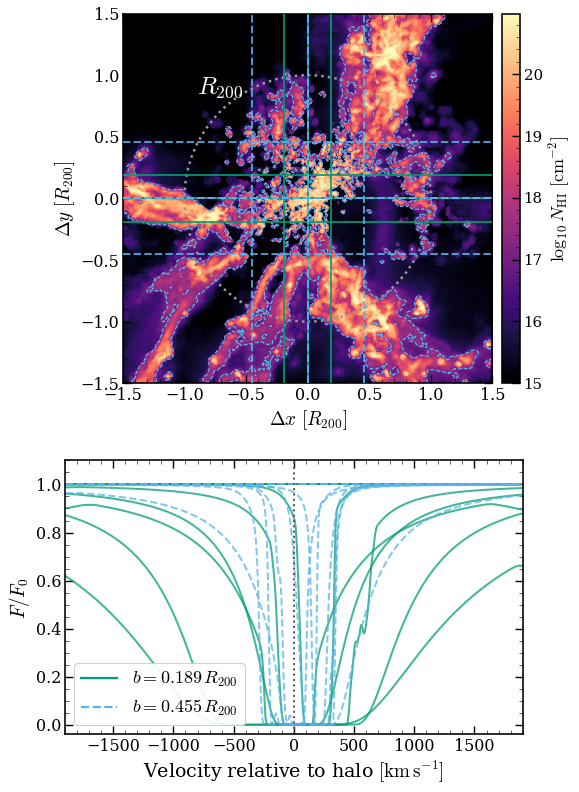

In [7]:
# =============================================================================
# CELL 7 -- FIG 1  (plots/diff_impact_parameters_visualization_altHalo.pdf)
#
# Elements drawn, all of which the caption must name:
#   colour map      projected log10 N_HI in a +/-5 R200 slab
#   dashed circle   R200
#   straight lines  the 8 sightlines lying in the plane of the map
#   dashed contour  the 10^17.2 cm^-2 HCD threshold  (SHOW_HCD_CONTOUR)
#   thin curves     individual HCD-only transmitted-flux profiles
#
# The 4 sightlines whose LOS is the projection axis are not drawn as markers
# in the map panel (top panel has no dots); only the 8 in-plane sightlines
# show up there, as lines.
#
# No mean profile: averaging over sightlines that do and do not host an HCD
# gives a curve that describes none of them, and the legend already reports the
# incidence.
#
# Note: this halo was chosen for the multi-basin resolution check now living
# in 01.5.1_'s FIG 2, not for this map, so it need not look like the
# manuscript's Fig. 1 example -- the filename is suffixed "_altHalo" so it
# never overwrites 01_'s output.
# =============================================================================
plt.close('all')

B_COLORS = {B_LIST[0]: "#009E73", B_LIST[1]: "#56B4E9"}
B_LS = {B_LIST[0]: "-", B_LIST[1]: "--"}
AXNAME = "xyz"

fig1, (axm, axf) = plt.subplots(
    2, 1, figsize=(8.2, 13.0),
    gridspec_kw=dict(height_ratios=[1.35, 1.0], hspace=0.24))

# --- map panel ---------------------------------------------------------------
cmap = mpl.colormaps['magma'].copy()
cmap.set_bad(cmap(0.0))

im = axm.imshow(logN.T, origin='lower', cmap=cmap,
                extent=[-MAP_HALF_R200, MAP_HALF_R200,
                        -MAP_HALF_R200, MAP_HALF_R200],
                vmin=MAP_VMIN_LOGN, vmax=vmax_logN,
                aspect='equal', interpolation='nearest')
cb = fig1.colorbar(im, ax=axm, fraction=0.046, pad=0.02)
cb.set_label(r'$\log_{10} N_{\rm HI}\ [\mathrm{cm^{-2}}]$', fontsize=18)
cb.ax.tick_params(labelsize=15)

if SHOW_HCD_CONTOUR:
    cc = 0.5 * (edges[1:] + edges[:-1]) / r200
    axm.contour(cc, cc, logN.T, levels=[HCD_LOG_NHI],
                colors=[OI["sky"]], linewidths=1.2, linestyles='--')

axm.add_patch(plt.Circle((0, 0), 1.0, fill=False, ec="#999999", lw=2.5,
                         ls=':'))

axm.text(-0.90, 0.85, r'$R_{200}$', color="white", fontsize=25)
        # bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=2)

for b in B_LIST:
    c = B_COLORS[b]
    for sk in by_b[b]:
        off = np.zeros(3)
        free = [k for k in range(3) if k != sk['axis']]
        tag = sk['position_tag']
        off[free[0]] = b if tag == "Right" else (-b if tag == "Left" else 0.0)
        off[free[1]] = b if tag == "Top" else (-b if tag == "Bottom" else 0.0)
        if sk['axis'] == MAP_AXIS:
            continue          # LOS-aligned sightline: no dot in this panel
        elif sk['axis'] == ax_p:
            axm.axhline(off[ax_q], color=c, lw=2.0, ls=B_LS[b], alpha=0.85, zorder=4)
        else:
            axm.axvline(off[ax_p], color=c, lw=2.0, ls=B_LS[b], alpha=0.85, zorder=4)

axm.set_xlim(-MAP_HALF_R200, MAP_HALF_R200)
axm.set_ylim(-MAP_HALF_R200, MAP_HALF_R200)
axm.set_xlabel(rf'$\Delta {AXNAME[ax_p]}\ [R_{{200}}]$')
axm.set_ylabel(rf'$\Delta {AXNAME[ax_q]}\ [R_{{200}}]$')

# --- flux panel: individual sightlines only ----------------------------------
handles, labels = [], []
for b in B_LIST:
    c, ls = B_COLORS[b], B_LS[b]
    for r in by_b[b]:
        axf.plot(v_grid1, np.asarray(r['flux'], float),
                 color=c, ls=ls, lw=2.0, alpha=0.75, zorder=2)
    handles.append(Line2D([], [], color=c, ls=ls, lw=2.2))
    labels.append(rf'$b = {b:.3f}\,R_{{200}}$')

axf.axvline(0.0, color='0.35', lw=2.0, ls=':')
axf.set_xlim(-1900, 1900)
axf.set_ylim(-0.04, 1.10)
axf.set_xlabel(r'Velocity relative to halo $[\mathrm{km\,s^{-1}}]$')
axf.set_ylabel(r'$F/F_0$')
axf.legend(handles, labels, loc='lower left', fontsize=18)

for ax in (axm, axf):
    ax.grid(False)
    for s in ax.spines.values():
        s.set_linewidth(1.6)

out1 = os.path.join(PLOT_DIR, "diff_impact_parameters_visualization_altHalo.pdf")
fig1.savefig(out1, bbox_inches='tight')
if hasattr(fig1.canvas, "header_visible"):
    fig1.canvas.header_visible = False
print(f"saved {out1}")
plt.show()
